# Bank Marketing — Baseline Classification Model

## Objective

This notebook establishes baseline performance for the Bank Marketing
classification problem.

A majority-class dummy classifier is evaluated first. A Logistic
Regression model will then be trained using the preprocessing pipeline
defined in the previous stage.

The models are evaluated using metrics appropriate for an imbalanced
classification problem.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    accuracy_score,
    average_precision_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [2]:
df = pd.read_csv(
    "../data/raw/bank-full.csv",
    sep=";",
)

In [3]:
X = df.drop(columns=["y", "duration"]).copy()

y = df["y"].map({
    "no": 0,
    "yes": 1,
})

In [4]:
X["previously_contacted"] = (
    X["pdays"] != -1
).astype("int8")

X["pdays"] = X["pdays"].replace(-1, 0)

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

In [6]:
print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Positive training rate:", y_train.mean().round(4))
print("Positive test rate:", y_test.mean().round(4))

Training shape: (36168, 16)
Test shape: (9043, 16)
Positive training rate: 0.117
Positive test rate: 0.117


In [7]:
def calculate_classification_metrics(
    y_true,
    y_pred,
    y_probability,
):
    return pd.Series({
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(
            y_true,
            y_pred,
            zero_division=0,
        ),
        "recall": recall_score(
            y_true,
            y_pred,
            zero_division=0,
        ),
        "f1_score": f1_score(
            y_true,
            y_pred,
            zero_division=0,
        ),
        "roc_auc": roc_auc_score(
            y_true,
            y_probability,
        ),
        "average_precision": average_precision_score(
            y_true,
            y_probability,
        ),
    })

## Majority-Class Baseline

The dummy classifier always predicts the most frequent target class.
Its results represent the minimum performance that a useful model
should improve upon.

In [8]:
dummy_model = DummyClassifier(
    strategy="most_frequent",
)

dummy_model.fit(X_train, y_train)

,"strategy strategy: {""most_frequent"", ""prior"", ""stratified"", ""uniform"", ""constant""}, default=""prior""Strategy to use to generate predictions.* ""most_frequent"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit`. The `predict_proba` method returns the matching one-hot encoded vector.* ""prior"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit` (like ""most_frequent""). ``predict_proba`` always returns the empirical class distribution of `y` also known as the empirical class prior distribution.* ""stratified"": the `predict_proba` method randomly samples one-hot vectors from a multinomial distribution parametrized by the empirical class prior probabilities. The `predict` method returns the class label which got probability one in the one-hot vector of `predict_proba`. Each sampled row of both methods is therefore independent and identically distributed.* ""uniform"": generates predictions uniformly at random from the list of unique classes observed in `y`, i.e. each class has equal probability.* ""constant"": always predicts a constant label that is provided by the user. This is useful for metrics that evaluate a non-majority class. .. versionchanged:: 0.24 The default value of `strategy` has changed to ""prior"" in version 0.24.",'most_frequent'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness to generate the predictions when``strategy='stratified'`` or ``strategy='uniform'``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"constant constant: int or str or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None
Name,Type,Value
"class_prior_ class_prior_: ndarray of shape (n_classes,) or list of such arraysFrequency of each class observed in `y`. For multioutput classificationproblems, this is computed independently for each output.","ndarray[float64](2,)","[0.88,0.12]"
"classes_ classes_: ndarray of shape (n_classes,) or list of such arraysUnique class labels observed in `y`. For multi-output classificationproblems, this attribute is a list of arrays as each output has anindependent set of possible classes.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X` hasfeature names that are all strings.","ndarray[object](16,)","['age','job','marital',...,'previous','poutcome','previously_contacted']"
n_classes_ n_classes_: int or list of intNumber of label for each output.,int,2
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`.,int,16
n_outputs_ n_outputs_: intNumber of outputs.,int,1
sparse_output_ sparse_output_: boolTrue if the array returned from predict is to be in sparse CSC format.Is automatically set to True if the input `y` is passed in sparseformat.,bool,False


In [9]:
dummy_predictions = dummy_model.predict(X_test)

dummy_probabilities = dummy_model.predict_proba(
    X_test
)[:, 1]

In [10]:
dummy_results = calculate_classification_metrics(
    y_test,
    dummy_predictions,
    dummy_probabilities,
)

dummy_results.to_frame(
    name="majority_baseline"
)

,majority_baseline
accuracy,0.883003
precision,0.000000
recall,0.000000
f1_score,0.000000
roc_auc,0.500000
average_precision,0.116997


## Logistic Regression Baseline

In [11]:
categorical_features = X_train.select_dtypes(
    include=["object", "string"]
).columns.tolist()

numeric_features = [
    "age",
    "balance",
    "day",
    "campaign",
    "pdays",
    "previous",
]

binary_features = [
    "previously_contacted",
]

In [12]:
numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median"),
        ),
        (
            "scaler",
            StandardScaler(),
        ),
    ]
)

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent"),
        ),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore"),
        ),
    ]
)

In [13]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_transformer,
            numeric_features,
        ),
        (
            "categorical",
            categorical_transformer,
            categorical_features,
        ),
        (
            "binary",
            "passthrough",
            binary_features,
        ),
    ]
)

In [14]:
logistic_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor,
        ),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=42,
            ),
        ),
    ]
)

In [15]:
logistic_pipeline.fit(
    X_train,
    y_train,
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['age','job','marital',...,'previous','poutcome','previously_contacted']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

In [16]:
logistic_predictions = logistic_pipeline.predict(
    X_test
)

logistic_probabilities = logistic_pipeline.predict_proba(
    X_test
)[:, 1]

In [17]:
logistic_results = calculate_classification_metrics(
    y_test,
    logistic_predictions,
    logistic_probabilities,
)

In [18]:
model_comparison = pd.concat(
    [
        dummy_results.rename("majority_baseline"),
        logistic_results.rename("logistic_regression"),
    ],
    axis=1,
)

model_comparison

,majority_baseline,logistic_regression
accuracy,0.883003,0.893509
precision,0.000000,0.667845
recall,0.000000,0.178639
f1_score,0.000000,0.281879
roc_auc,0.500000,0.771788
average_precision,0.116997,0.410993


In [19]:
print(
    classification_report(
        y_test,
        logistic_predictions,
        target_names=["no", "yes"],
        zero_division=0,
    )
)

              precision    recall  f1-score   support

          no       0.90      0.99      0.94      7985
         yes       0.67      0.18      0.28      1058

    accuracy                           0.89      9043
   macro avg       0.78      0.58      0.61      9043
weighted avg       0.87      0.89      0.87      9043



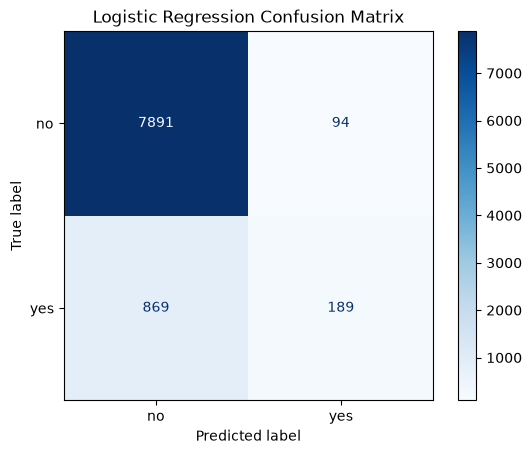

In [20]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    logistic_predictions,
    display_labels=["no", "yes"],
    cmap="Blues",
    values_format="d",
)

plt.title("Logistic Regression Confusion Matrix")
plt.show()

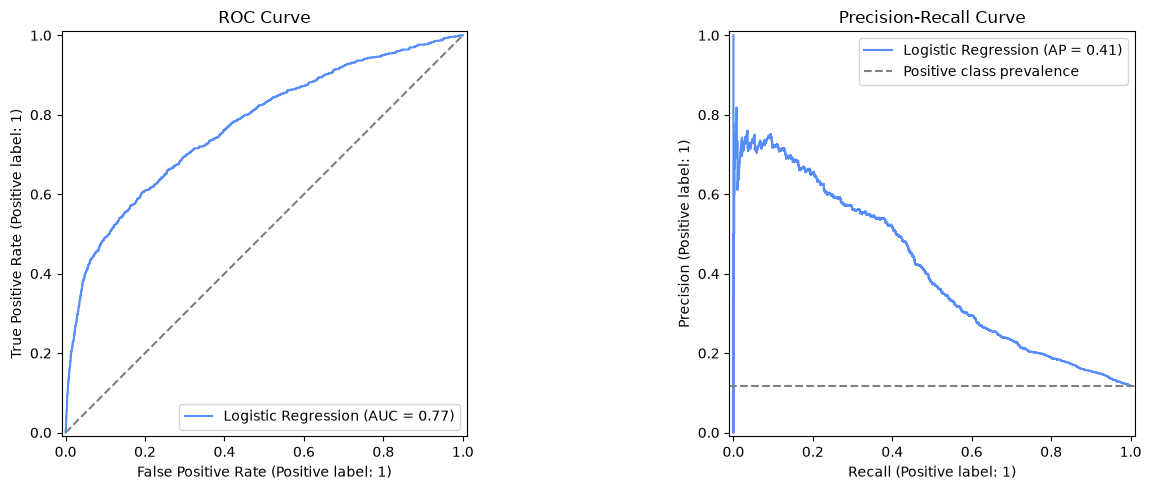

In [21]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5),
)

RocCurveDisplay.from_predictions(
    y_test,
    logistic_probabilities,
    name="Logistic Regression",
    ax=axes[0],
)

axes[0].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
)

axes[0].set_title("ROC Curve")

PrecisionRecallDisplay.from_predictions(
    y_test,
    logistic_probabilities,
    name="Logistic Regression",
    ax=axes[1],
)

axes[1].axhline(
    y=y_test.mean(),
    linestyle="--",
    color="gray",
    label="Positive class prevalence",
)

axes[1].set_title("Precision-Recall Curve")
axes[1].legend()

plt.tight_layout()
plt.show()

## Baseline Model Findings

### Majority-class baseline

- The majority-class classifier obtains an accuracy of 88.30% by predicting every customer as a non-subscriber.
- Its precision, recall, and F1-score for the positive class are all zero because it does not identify any actual subscribers.
- Its ROC-AUC is 0.50 and its average precision is 0.117, corresponding approximately to the prevalence of the positive class.

### Logistic Regression baseline

- Logistic Regression increases accuracy from 88.30% to 89.35%. The relatively small accuracy improvement confirms that accuracy alone is not sufficient for evaluating this imbalanced problem.
- The model achieves a precision of 66.78%, meaning that approximately two out of three customers predicted as subscribers actually subscribed.
- Recall is only 17.86%, meaning that the model identifies 189 of the 1,058 actual subscribers and misses 869.
- The positive-class F1-score is 0.282, reflecting the imbalance between relatively high precision and low recall.
- ROC-AUC increases to 0.772, indicating that the model can rank positive observations above negative observations substantially better than random classification.
- Average precision increases from 0.117 to 0.411, showing a meaningful improvement over the class-prevalence baseline.

### Interpretation

- The Logistic Regression model contains useful predictive information, but the default classification threshold of 0.5 produces a conservative model with low positive-class recall.
- Class weighting or threshold adjustment may improve recall, although this will likely reduce precision and overall accuracy.
- Future model and threshold choices should be evaluated through cross-validation on the training data rather than repeatedly optimized against the test set.
- The current Logistic Regression results provide the reference baseline for evaluating more advanced models.